In [1]:
import torch
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import graph_utils as gu


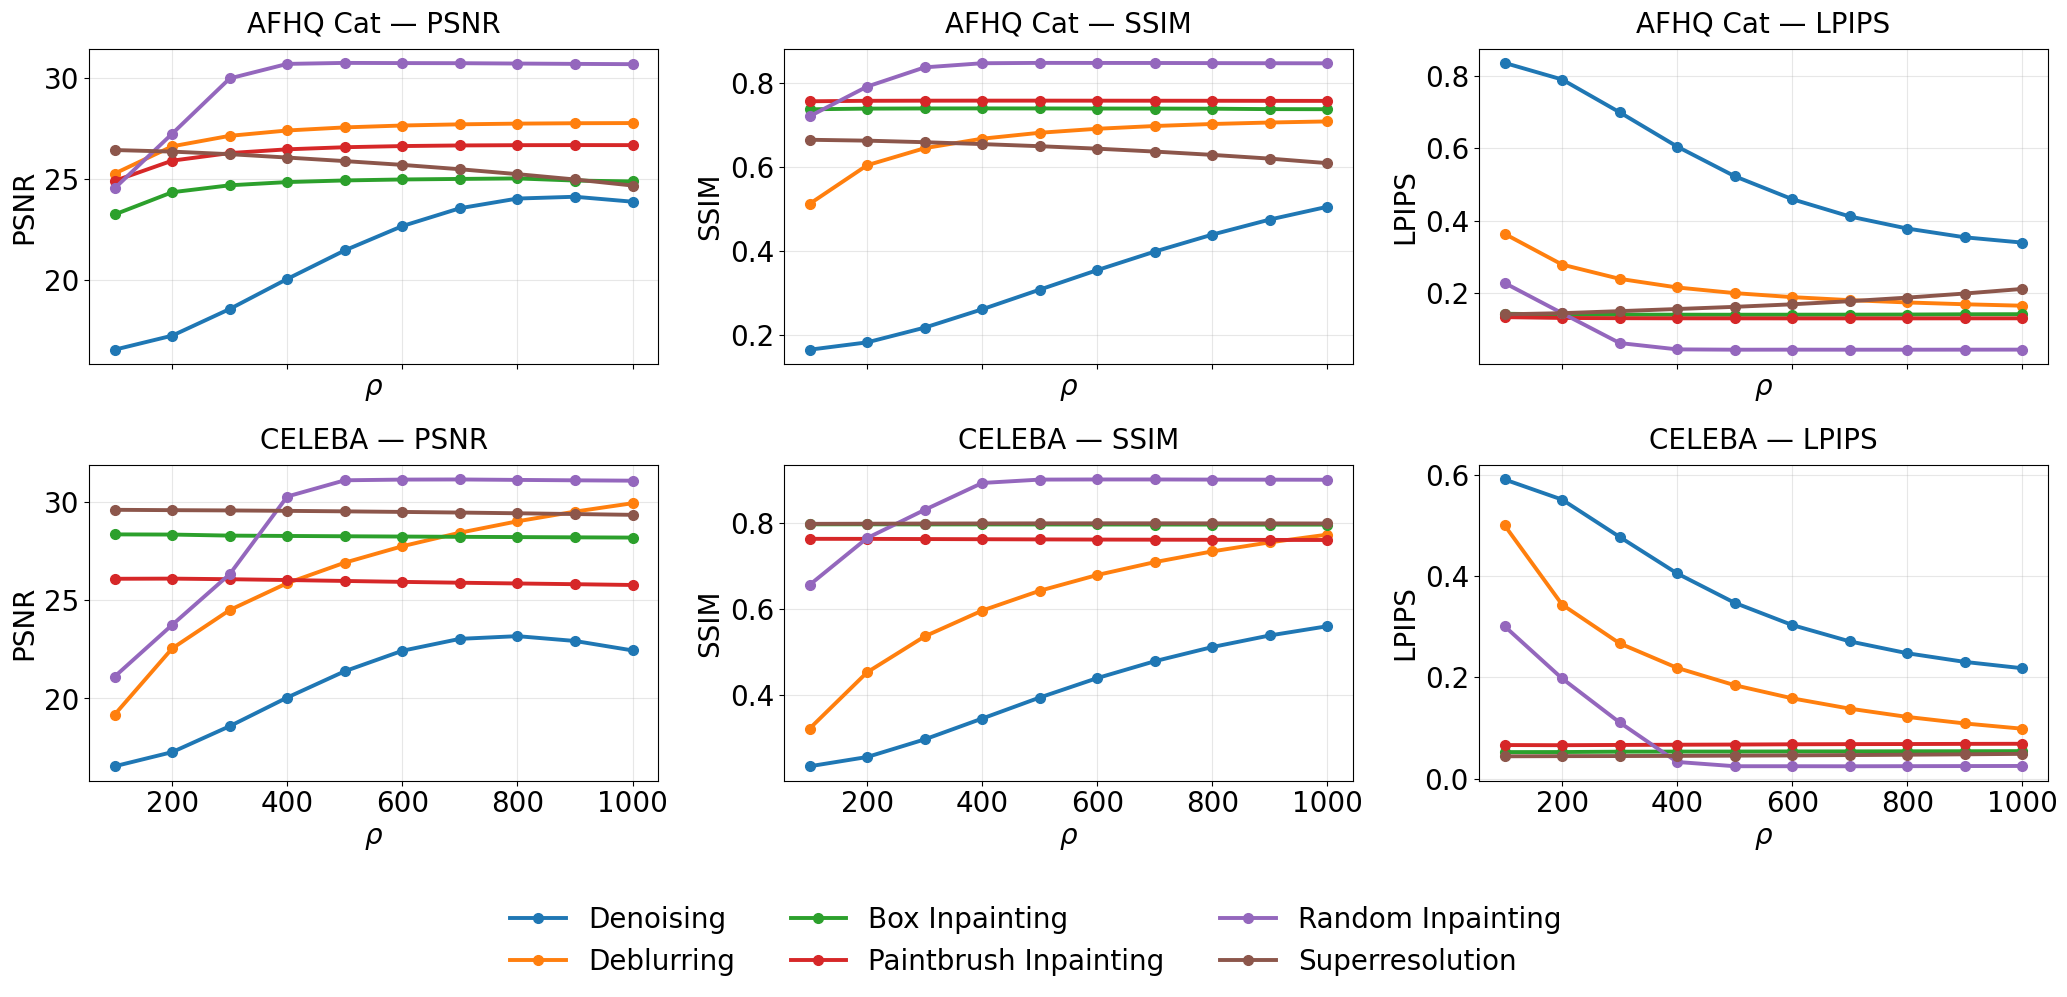

Saved: all_datasets_metrics_vs_rho_admm.png


In [4]:
BASE_DIRS = [
    Path("results/afhq_cat_admm_rho_graph/ot"),
    Path("results/celeba_admm_rho_graph/ot"),
]

DATASET_NAMES = [
    "AFHQ Cat",
    "CELEBA",
]

METHODS = [
    "denoising",
    "gaussian_deblurring_FFT",
    "inpainting",
    "paintbrush_inpainting",
    "random_inpainting",
    "superresolution",
]

METRIC_CONFIG = {
    "final_psnr.txt":  ("psnr_rec", "PSNR"),
    "final_ssim.txt":  ("ssim_rec", "SSIM"),
    "final_lpips.txt": ("lpips_rec", "LPIPS"),
}

gu.plot_rho_analysis(
    base_dirs=BASE_DIRS,
    dataset_names=DATASET_NAMES,
    methods=METHODS,
    metric_config=METRIC_CONFIG,
    save_name="all_datasets_metrics_vs_rho_admm.png"
)

## Ablations

In [9]:
# ROOT_DIR = Path("results/afhq_cat_ablation/ot")
# OUT_XLSX = "ablation_summary_afhq_cat.xlsx"

ROOT_DIR = Path("results/celeba_ablation/ot")
OUT_XLSX = "ablation_summary_celeba.xlsx"

METHODS = [
    "pnp_flow_admm",
    "pnp_flow_fbs",
]

METRIC_FILES = {
    "psnr": "final_psnr.txt",
    "ssim": "final_ssim.txt",
    "lpips": "final_lpips.txt",
}

df = gu.collect_results(METHODS, METRIC_FILES, ROOT_DIR)

if df.empty:
    print("No matching results found.")
else:
    gu.save_outputs(df, OUT_XLSX)
    print(f"Saved Excel: {OUT_XLSX}")
    display(df)

Saved Excel: ablation_summary_celeba.xlsx


,task,method,adaptive_noise,deterministic_noise,psnr_rec,ssim_rec,lpips_rec,psnr_noisy,ssim_noisy,lpips_noisy
0,denoising,pnp_flow_admm,False,False,15.1315,0.5206,0.3585,16.4785,0.2326,0.5784
1,denoising,pnp_flow_admm,False,True,22.5268,0.5369,0.2058,16.4785,0.2326,0.5784
2,denoising,pnp_flow_admm,True,False,20.1879,0.6049,0.1853,16.4785,0.2326,0.5784
3,denoising,pnp_flow_fbs,False,None,29.8221,0.8665,0.0956,16.4785,0.2326,0.5784
4,denoising,pnp_flow_fbs,True,None,17.3261,0.2588,0.5505,16.4785,0.2326,0.5784
5,gaussian_deblurring_FFT,pnp_flow_admm,False,False,34.0815,0.9353,0.0538,27.8126,0.7395,0.1279
6,gaussian_deblurring_FFT,pnp_flow_admm,False,True,29.0233,0.7339,0.1159,27.8126,0.7395,0.1279
7,gaussian_deblurring_FFT,pnp_flow_admm,True,False,31.1624,0.8222,0.0683,27.8126,0.7395,0.1279
8,gaussian_deblurring_FFT,pnp_flow_fbs,False,None,28.0895,0.8174,0.1551,27.8126,0.7395,0.1279
9,gaussian_deblurring_FFT,pnp_flow_fbs,True,None,31.8116,0.8946,0.0326,27.8126,0.7395,0.1279


## Results on single image for comparison

In [5]:
ROOT_DIR = Path("results/celeba/ot")

df = gu.extract_basic_metrics(ROOT_DIR, "metrics.xlsx")
display(df)
print(ROOT_DIR)

,task,method,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,psnr_rec,psnr_noisy
0,denoising,d_flow,0.3208,0.2327,0.3260,0.5788,19.4559,16.4795
1,denoising,flow_priors,0.5434,0.2327,0.2028,0.5788,23.9525,16.4795
2,denoising,ot_ode,0.8080,0.2327,0.0482,0.5788,28.6395,16.4795
3,denoising,pnp_flow_admm,0.6069,0.2327,0.1846,0.5788,20.1360,16.4795
4,denoising,pnp_flow_fbs,0.8693,0.2327,0.0900,0.5788,29.8298,16.4795
5,gaussian_deblurring_FFT,d_flow,0.8671,0.7405,0.0648,0.1270,30.2572,27.7588
6,gaussian_deblurring_FFT,flow_priors,0.8694,0.7405,0.0427,0.1270,29.9172,27.7588
7,gaussian_deblurring_FFT,ot_ode,0.9160,0.7405,0.0323,0.1270,32.7765,27.7588
8,gaussian_deblurring_FFT,pnp_flow_admm,0.8223,0.7405,0.0684,0.1270,31.1041,27.7588
9,gaussian_deblurring_FFT,pnp_flow_fbs,0.8200,0.7405,0.1532,0.1270,27.9845,27.7588


results/celeba/ot


In [ ]:
ROOT_DIR = Path("results/celeba_100_new_important/ot")
df = gu.extract_basic_metrics(ROOT_DIR, "celeba_100_rho_1000.xlsx")
display(df)


,task,method,ssim_rec,ssim_noisy,lpips_rec,lpips_noisy,psnr_rec,psnr_noisy
0,denoising,d_flow,0.3171,0.2343,0.3427,0.5777,19.2875,16.4796
1,denoising,flow_priors,0.5448,0.2343,0.2010,0.5777,23.9430,16.4796
2,denoising,ot_ode,0.8055,0.2326,0.0496,0.5784,28.6005,16.4785
3,denoising,pnp_flow_admm,0.6049,0.2326,0.1853,0.5784,20.1879,16.4785
4,denoising,pnp_flow_fbs,0.8665,0.2326,0.0956,0.5784,29.8221,16.4785
5,gaussian_deblurring_FFT,d_flow,0.8716,0.7416,0.0587,0.1269,30.5437,27.7598
6,gaussian_deblurring_FFT,flow_priors,0.8672,0.7416,0.0443,0.1269,29.5483,27.7598
7,gaussian_deblurring_FFT,ot_ode,0.9136,0.7395,0.0344,0.1279,32.8298,27.8126
8,gaussian_deblurring_FFT,pnp_flow_admm,0.8222,0.7395,0.0683,0.1279,31.1624,27.8126
9,gaussian_deblurring_FFT,pnp_flow_fbs,0.8174,0.7395,0.1551,0.1279,28.0895,27.8126


results/celeba_100_new_important/ot


## Empirical Convergence

Saved: results/convergence_analysis_all_datasets.png


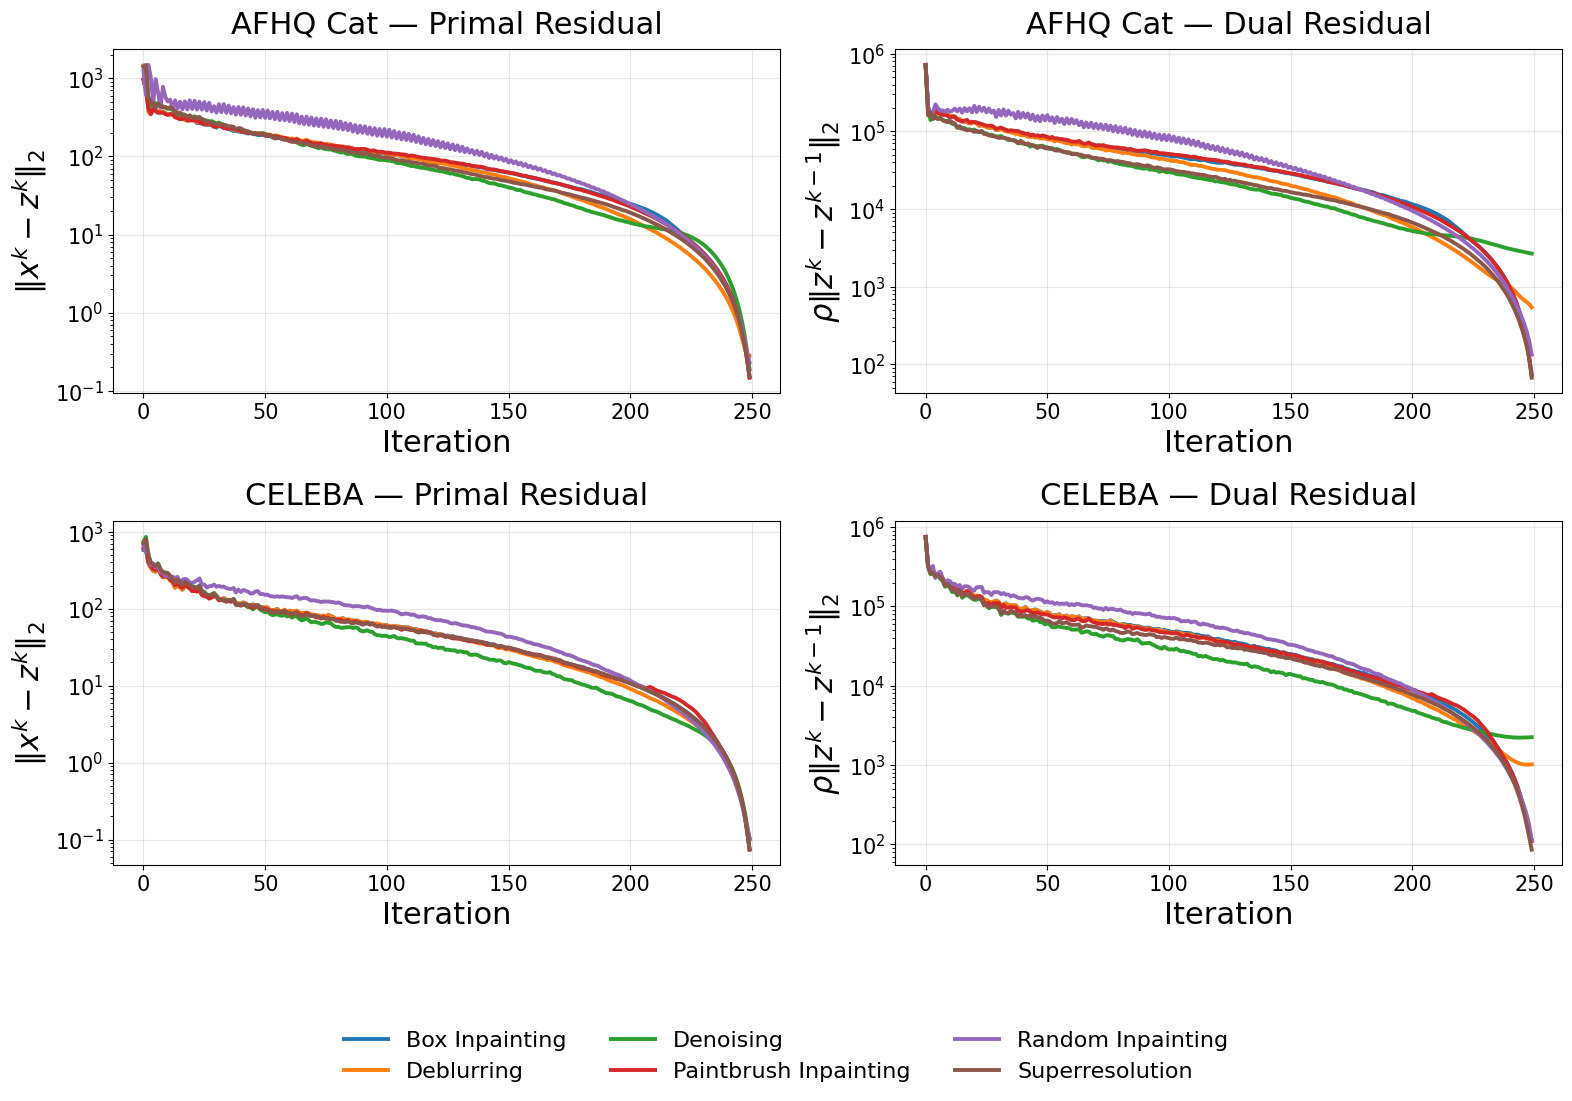

In [2]:
ROOT_DIRS = [
    Path("results/afhq_cat_convergence_analysis/ot"),
    Path("results/celeba_convergence_analysis/ot"),
]

DATASET_NAMES = [
    "AFHQ Cat",
    "CELEBA",
]

gu.plot_convergence_two_datasets_shared_legend(
    root_dirs=ROOT_DIRS,
    dataset_names=DATASET_NAMES,
    batch=0,
    save_path=Path("results/convergence_analysis_all_datasets.png"),
    logy=True,
)

## Time and Memory

In [7]:
root_dir = Path("results/celeba/ot")

df_time_memory = gu.extract_time_memory_summary(root_dir)
gu.save_time_memory_summary(df_time_memory,xlsx_path="time_memory_summary_afhq_cat.xlsx")
display(df_time_memory)
print(root_dir)

,task,method,model,time_average,max_memory_average_gb,experiment_dir
0,denoising,d_flow,test,66.7318,13.337155,results/celeba/ot/denoising/d_flow/test/steps_...
1,denoising,flow_priors,test,35.5998,8.794555,results/celeba/ot/denoising/flow_priors/test/s...
2,denoising,ot_ode,test,14.3678,2.319093,results/celeba/ot/denoising/ot_ode/test/steps_...
3,denoising,pnp_flow_admm,test,6.4618,0.305060,results/celeba/ot/denoising/pnp_flow_admm/test...
4,denoising,pnp_flow_fbs,test,15.4524,0.300665,results/celeba/ot/denoising/pnp_flow_fbs/test/...
5,gaussian_deblurring_FFT,d_flow,test,68.2843,13.342605,results/celeba/ot/gaussian_deblurring_FFT/d_fl...
6,gaussian_deblurring_FFT,flow_priors,test,35.8619,8.795973,results/celeba/ot/gaussian_deblurring_FFT/flow...
7,gaussian_deblurring_FFT,ot_ode,test,14.1153,2.325956,results/celeba/ot/gaussian_deblurring_FFT/ot_o...
8,gaussian_deblurring_FFT,pnp_flow_admm,test,6.8855,0.305258,results/celeba/ot/gaussian_deblurring_FFT/pnp_...
9,gaussian_deblurring_FFT,pnp_flow_fbs,test,15.9127,0.302298,results/celeba/ot/gaussian_deblurring_FFT/pnp_...


results/celeba/ot
